# Dense $Q^T XQ$ versus rFFT2 plus packing

This notebook measures two mathematically equivalent routes to the
complete real Fourier matrix used by Fourier 2SDR. It asks when direct
packing from an existing rFFT2 half spectrum saves time and which costs
belong in a fair dense comparison.

It does not assume that the FFT route is always faster or uses less
peak memory. Conclusions are conditional on the recorded hardware,
software, dtype, batch size, and image dimension.


## Compared routes

From spatial $X$, compare public rFFT2 plus vectorized blocks with
separable $Q_h^T XQ_w$ using cached bases.

From an existing half spectrum $X^h$, compare trusted direct blocks,
irFFT2 plus cached $Q$, and irFFT2 plus cold
construction of $Q$. Host-to-device transfer is excluded. The
Kronecker operator is never allocated; only its theoretical size is
reported.


In [1]:
from __future__ import annotations

import hashlib
import os
import platform
import statistics
import time
from pathlib import Path

import matplotlib.pyplot as plt
import torch
from torch.utils.benchmark import Timer

from fourier_2sdr import real_fourier_transform
from fourier_2sdr.fourier import (
    _from_valid_rfft2,
    real_fourier_basis,
)

start = Path.cwd().resolve()
REPO_ROOT = next(
    (
        path
        for path in (start, *start.parents)
        if (path / "pyproject.toml").is_file()
        and (path / "src" / "fourier_2sdr").is_dir()
    ),
    None,
)
if REPO_ROOT is None:
    raise RuntimeError("Could not locate the repository root.")
os.chdir(REPO_ROOT)

source = REPO_ROOT / "src" / "fourier_2sdr" / "fourier.py"
source_sha256 = hashlib.sha256(source.read_bytes()).hexdigest()
torch.manual_seed(20260818)
torch.backends.cuda.matmul.allow_tf32 = False

environment = {
    "python": platform.python_version(),
    "torch": torch.__version__,
    "cpu": platform.processor() or platform.machine(),
    "cpu_threads": torch.get_num_threads(),
    "cuda_available": torch.cuda.is_available(),
    "gpu": (
        torch.cuda.get_device_name(0)
        if torch.cuda.is_available()
        else None
    ),
    "tf32": torch.backends.cuda.matmul.allow_tf32,
    "dtype": "float32",
    "fourier_source_sha256": source_sha256,
}
environment


{'python': '3.13.12',
 'torch': '2.11.0+cu128',
 'cpu': 'x86_64',
 'cpu_threads': 14,
 'cuda_available': True,
 'gpu': 'NVIDIA GeForce RTX 5070',
 'tf32': False,
 'dtype': 'float32',
 'fourier_source_sha256': '9d0301d7df4c12167bbf5acb23f04826b9b01496df8f12c4c5bee01b71b0106e'}

In [2]:
def cpu_time(fn, min_run_time=0.2):
    measurement = Timer(
        stmt="fn()",
        globals={"fn": fn},
        num_threads=torch.get_num_threads(),
    ).blocked_autorange(min_run_time=min_run_time)
    return {
        "median_ms": measurement.median * 1e3,
        "iqr_ms": measurement.iqr * 1e3,
    }


def gpu_time(fn, inner_loops, repeats=7, warmup=5):
    for _ in range(warmup):
        fn()
    torch.cuda.synchronize()
    samples = []
    for _ in range(repeats):
        torch.cuda.synchronize()
        started = time.perf_counter()
        for _ in range(inner_loops):
            fn()
        torch.cuda.synchronize()
        samples.append(
            1e3 * (time.perf_counter() - started) / inner_loops
        )
    ordered = sorted(samples)
    return {
        "median_ms": statistics.median(samples),
        "iqr_ms": ordered[5] - ordered[1],
    }


def gpu_peak_extra_mib(fn):
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()
    baseline = torch.cuda.memory_allocated()
    output = fn()
    torch.cuda.synchronize()
    peak = torch.cuda.max_memory_allocated() - baseline
    del output
    return peak / 2**20


def inner_loops(total_pixels):
    if total_pixels < 2_000_000:
        return 100
    if total_pixels < 20_000_000:
        return 20
    return 5


## GPU scaling from spatial input

Batch size is one. Dense uses a precomputed $Q_d$; the public route
includes rFFT2 and packing. TF32 is disabled for numerical comparability.


In [3]:
gpu_scaling = []
if torch.cuda.is_available():
    for dimension in (32, 64, 130, 256, 512, 1024, 2048):
        images = torch.randn(1, dimension, dimension, device="cuda")
        q = real_fourier_basis(
            dimension, dtype=torch.float32, device="cuda"
        )
        dense = lambda: q.T @ images @ q
        fft_pack = lambda: real_fourier_transform(images)
        loops = inner_loops(images.numel())
        dense_time = gpu_time(dense, loops)
        fft_time = gpu_time(fft_pack, loops)
        gpu_scaling.append(
            {
                "dimension": dimension,
                "dense_ms": dense_time["median_ms"],
                "dense_iqr_ms": dense_time["iqr_ms"],
                "fft_pack_ms": fft_time["median_ms"],
                "fft_pack_iqr_ms": fft_time["iqr_ms"],
                "dense_over_fft": (
                    dense_time["median_ms"] / fft_time["median_ms"]
                ),
            }
        )
        del images, q
        torch.cuda.empty_cache()
gpu_scaling


[{'dimension': 32,
  'dense_ms': 0.034605819964781404,
  'dense_iqr_ms': 0.004493729793466628,
  'fft_pack_ms': 0.3664101999311242,
  'fft_pack_iqr_ms': 0.011725730146281421,
  'dense_over_fft': 0.09444556939541097},
 {'dimension': 64,
  'dense_ms': 0.03743367997230962,
  'dense_iqr_ms': 0.005944509903201833,
  'fft_pack_ms': 0.3654190999804996,
  'fft_pack_iqr_ms': 0.017471629980718717,
  'dense_over_fft': 0.10244040329119974},
 {'dimension': 130,
  'dense_ms': 0.035249210050096735,
  'dense_iqr_ms': 0.002729940169956535,
  'fft_pack_ms': 0.3706730098929256,
  'fft_pack_iqr_ms': 0.01818622011342086,
  'dense_over_fft': 0.09509516233803748},
 {'dimension': 256,
  'dense_ms': 0.03854656999465078,
  'dense_iqr_ms': 0.01337362002232112,
  'fft_pack_ms': 0.4042528998979833,
  'fft_pack_iqr_ms': 0.08027481992030516,
  'dense_over_fft': 0.09535261219988364},
 {'dimension': 512,
  'dense_ms': 0.04684377010562457,
  'dense_iqr_ms': 0.008653490076540038,
  'fft_pack_ms': 0.36983984013204463,
  

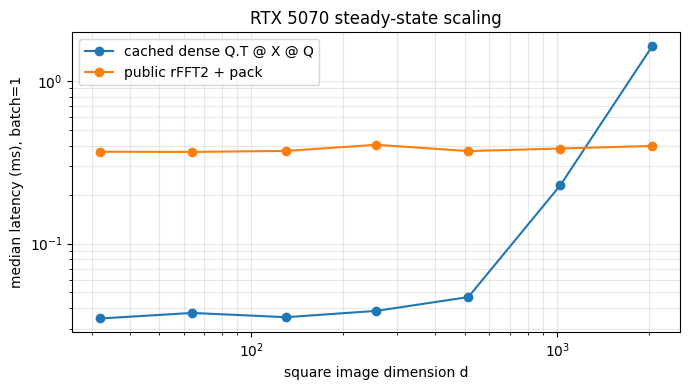

In [4]:
if gpu_scaling:
    dimensions = [row["dimension"] for row in gpu_scaling]
    plt.figure(figsize=(7, 4))
    plt.loglog(
        dimensions,
        [row["dense_ms"] for row in gpu_scaling],
        "o-",
        label="cached dense Q.T @ X @ Q",
    )
    plt.loglog(
        dimensions,
        [row["fft_pack_ms"] for row in gpu_scaling],
        "o-",
        label="public rFFT2 + pack",
    )
    plt.xlabel("square image dimension d")
    plt.ylabel("median latency (ms), batch=1")
    plt.title("RTX 5070 steady-state scaling")
    plt.grid(True, which="both", alpha=0.3)
    plt.legend()
    plt.tight_layout()


## Existing half spectrum

This is the pipeline comparison used in the paper. Cached and cold dense routes
both include irFFT2; the cold route additionally constructs $Q_d$ once.


In [5]:
existing_spectrum_rows = []
if torch.cuda.is_available():
    for dimension, batch in (
        (130, 64),
        (130, 5000),
        (512, 16),
        (2048, 1),
    ):
        images = torch.randn(batch, dimension, dimension, device="cuda")
        spectra = torch.fft.rfft2(images, norm="ortho")
        q = real_fourier_basis(
            dimension, dtype=torch.float32, device="cuda"
        )

        trusted = lambda: _from_valid_rfft2(
            spectra, (dimension, dimension)
        )
        cached = lambda: (
            q.T
            @ torch.fft.irfft2(
                spectra, s=(dimension, dimension), norm="ortho"
            )
            @ q
        )

        def cold():
            fresh_q = real_fourier_basis(
                dimension, dtype=torch.float32, device="cuda"
            )
            spatial = torch.fft.irfft2(
                spectra, s=(dimension, dimension), norm="ortho"
            )
            return fresh_q.T @ spatial @ fresh_q

        loops = inner_loops(images.numel())
        methods = {
            "trusted_pack": trusted,
            "irfft_cached_q": cached,
            "irfft_cold_q": cold,
        }
        row = {
            "dimension": dimension,
            "batch": batch,
            "q_resident_mib": (
                q.numel() * q.element_size() / 2**20
            ),
        }
        for name, fn in methods.items():
            timing = gpu_time(fn, loops)
            row[f"{name}_ms"] = timing["median_ms"]
            row[f"{name}_iqr_ms"] = timing["iqr_ms"]
            row[f"{name}_peak_extra_mib"] = gpu_peak_extra_mib(fn)
        existing_spectrum_rows.append(row)
        del images, spectra, q
        torch.cuda.empty_cache()

for row in existing_spectrum_rows:
    print(row)


{'dimension': 130, 'batch': 64, 'q_resident_mib': 0.0644683837890625, 'trusted_pack_ms': 0.2020888400147669, 'trusted_pack_iqr_ms': 0.00994220987195149, 'trusted_pack_peak_extra_mib': 10.376953125, 'irfft_cached_q_ms': 0.12995894998311996, 'irfft_cached_q_iqr_ms': 0.0057617500715423375, 'irfft_cached_q_peak_extra_mib': 12.5048828125, 'irfft_cold_q_ms': 3.56134668996674, 'irfft_cold_q_iqr_ms': 0.2565105797839351, 'irfft_cold_q_peak_extra_mib': 12.56982421875}
{'dimension': 130, 'batch': 5000, 'q_resident_mib': 0.0644683837890625, 'trusted_pack_ms': 12.277548800921068, 'trusted_pack_iqr_ms': 0.09624759841244668, 'trusted_pack_peak_extra_mib': 814.0, 'irfft_cached_q_ms': 12.570243401569314, 'irfft_cached_q_iqr_ms': 0.12975280114915222, 'irfft_cached_q_peak_extra_mib': 978.34228515625, 'irfft_cold_q_ms': 15.170667599886656, 'irfft_cold_q_iqr_ms': 0.3369739977642894, 'irfft_cold_q_peak_extra_mib': 978.4072265625}
{'dimension': 512, 'batch': 16, 'q_resident_mib': 1.0, 'trusted_pack_ms': 0.22

## Paper-size batch scaling

This holds $d=130$ fixed. It prevents a large-image crossover from
being misreported as a universal speedup for the image size of the paper.


In [6]:
paper_batch_rows = []
if torch.cuda.is_available():
    dimension = 130
    q = real_fourier_basis(
        dimension, dtype=torch.float32, device="cuda"
    )
    for batch in (1, 64, 256, 1000, 5000):
        images = torch.randn(batch, dimension, dimension, device="cuda")
        spectra = torch.fft.rfft2(images, norm="ortho")
        trusted = lambda: _from_valid_rfft2(
            spectra, (dimension, dimension)
        )
        cached = lambda: (
            q.T
            @ torch.fft.irfft2(
                spectra, s=(dimension, dimension), norm="ortho"
            )
            @ q
        )
        loops = inner_loops(images.numel())
        direct_time = gpu_time(trusted, loops)
        cached_time = gpu_time(cached, loops)
        paper_batch_rows.append(
            {
                "batch": batch,
                "trusted_pack_ms": direct_time["median_ms"],
                "irfft_cached_q_ms": cached_time["median_ms"],
                "cached_dense_over_pack": (
                    cached_time["median_ms"]
                    / direct_time["median_ms"]
                ),
            }
        )
        del images, spectra
        torch.cuda.empty_cache()
paper_batch_rows


[{'batch': 1,
  'trusted_pack_ms': 0.20461712003452703,
  'irfft_cached_q_ms': 0.07618870004080236,
  'cached_dense_over_pack': 0.3723476316544104},
 {'batch': 64,
  'trusted_pack_ms': 0.19905182998627424,
  'irfft_cached_q_ms': 0.12811535998480394,
  'cached_dense_over_pack': 0.6436281444568394},
 {'batch': 256,
  'trusted_pack_ms': 0.23768895043758675,
  'irfft_cached_q_ms': 0.46739529934711754,
  'cached_dense_over_pack': 1.9664157651697316},
 {'batch': 1000,
  'trusted_pack_ms': 2.135179100150708,
  'irfft_cached_q_ms': 2.495536250353325,
  'cached_dense_over_pack': 1.1687713926092578},
 {'batch': 5000,
  'trusted_pack_ms': 11.752737400820479,
  'irfft_cached_q_ms': 12.133926601381972,
  'cached_dense_over_pack': 1.0324340779140426}]

## CPU reference

CPU cases are smaller and use the current PyTorch thread count. They
make the notebook runnable without CUDA but do not determine the GPU
crossover.


In [7]:
cpu_rows = []
for dimension, batch in (
    (32, 1),
    (32, 64),
    (64, 1),
    (64, 64),
    (130, 1),
    (130, 64),
    (256, 1),
    (512, 1),
):
    images = torch.randn(batch, dimension, dimension)
    q = real_fourier_basis(dimension, dtype=torch.float32)
    dense = lambda: q.T @ images @ q
    fft_pack = lambda: real_fourier_transform(images)
    dense_time = cpu_time(dense)
    fft_time = cpu_time(fft_pack)
    cpu_rows.append(
        {
            "dimension": dimension,
            "batch": batch,
            "dense_ms": dense_time["median_ms"],
            "fft_pack_ms": fft_time["median_ms"],
            "dense_over_fft": (
                dense_time["median_ms"] / fft_time["median_ms"]
            ),
        }
    )
cpu_rows


[{'dimension': 32,
  'batch': 1,
  'dense_ms': 0.006566439500602428,
  'fft_pack_ms': 0.08074475399916992,
  'dense_over_fft': 0.08132341948394484},
 {'dimension': 32,
  'batch': 64,
  'dense_ms': 0.030943293997552246,
  'fft_pack_ms': 0.41804831998888403,
  'dense_over_fft': 0.07401846274223763},
 {'dimension': 64,
  'batch': 1,
  'dense_ms': 0.012879036003141664,
  'fft_pack_ms': 0.14725574799376773,
  'dense_over_fft': 0.08746032788945353},
 {'dimension': 64,
  'batch': 64,
  'dense_ms': 0.1240315698669292,
  'fft_pack_ms': 0.7449127901054453,
  'dense_over_fft': 0.1665048197781274},
 {'dimension': 130,
  'batch': 1,
  'dense_ms': 0.03389004549535457,
  'fft_pack_ms': 0.2002319629973499,
  'dense_over_fft': 0.16925392423887442},
 {'dimension': 130,
  'batch': 64,
  'dense_ms': 1.7649991990765557,
  'fft_pack_ms': 3.152738799690269,
  'dense_over_fft': 0.5598304557453198},
 {'dimension': 256,
  'batch': 1,
  'dense_ms': 0.14562703501724172,
  'fft_pack_ms': 0.4208626601030119,
  'den

## Kronecker size and interpretation

The vectorized identity

$$\operatorname{vec}(Z)
  =(Q_w^T\otimes Q_h^T)\operatorname{vec}(X)$$

is useful mathematically, but explicitly forming its $D\times D$
operator is unnecessary. Dense timing above already uses the efficient
separable alternative.


In [8]:
for dimension in (32, 130, 512, 2048):
    variables = dimension**2
    entries = variables**2
    gib = entries * 4 / 2**30
    print(
        f"d={dimension:4d}: D={variables:,}, "
        f"Kronecker entries={entries:,}, float32={gib:,.3f} GiB"
    )


d=  32: D=1,024, Kronecker entries=1,048,576, float32=0.004 GiB
d= 130: D=16,900, Kronecker entries=285,610,000, float32=1.064 GiB
d= 512: D=262,144, Kronecker entries=68,719,476,736, float32=256.000 GiB
d=2048: D=4,194,304, Kronecker entries=17,592,186,044,416, float32=65,536.000 GiB


## Interpretation

- Timing does not change the coordinate or statistical equivalence.
- At $d=130$, compare direct pack with both cold and cached dense routes.
  A cold-start advantage is not a universal steady-state speedup.
- The FFT route has better asymptotic arithmetic scaling, but the
  crossover is hardware- and batch-dependent.
- Direct packing is the natural interface when CTFs, masks, frequency
  bands, or spectral noise models already live on the half spectrum.
- Peak workspace must be reported as measured; no universal memory
  advantage is claimed.
- The manuscript claims a Fourier-native route and $O(D)$ block work
  after rFFT2. It does not claim a measured speedup.
